<a href="https://colab.research.google.com/github/Tolugold2704/Subsea-P-T-Design-Envelope-Construction_Visualization/blob/main/Corrosion_Rate__Prediction_Remaining_Life.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###QUESTION 1: CO2 Corrosion Modeling: de Waard-Milliams Model (1995)

The classic **de Waard-Milliams (1995)** model is widely used in the oil and gas industry to estimate the corrosion rate of carbon steel in the presence of wet carbon dioxide ($CO_2$). It is a semi-empirical model that estimates the corrosion rate as a function of temperature and the partial pressure of $CO_2$.

#### Model Equation
$$\log_{10}(V_{corr}) = 4.93 - \frac{1119}{T} + 0.58 \log_{10}(p_{CO_2})$$

Where:
* **$V_{corr}$**: Corrosion rate in millimeters per year ($	ext{mm/yr}$).
* **$T$**: Operating temperature in Kelvin ($	ext{K}$).
* **$p_{CO_2}$**: Partial pressure of $CO_2$ in bar, calculated as:
  $$p_{CO_2} = P_{total} \times y_{CO_2}$$
  *(where $y_{CO_2}$ is the mole fraction of $CO_2$ in the gas phase).*

#### Model Implementation & Validation
The Python function `de_waard_milliams_corrosion_rate` implements this formulation using Vectorized NumPy operations to safely handle scalar values as well as entire dataset arrays.

To ensure robustness, a unit testing suite is executed alongside the function, confirming:
1. **Standard Baseline Case:** Correct output of $\approx 12.97\text{ mm/yr}$ at standard parameters ($20^\circ\text{C}$ and $1\text{ bar } p_{CO_2}$).
2. **Temperature Trend:** Corrosion rates rise with an increase in system temperature.
3. **Pressure Trend:** Corrosion rates rise with an increase in $CO_2$ partial pressure.

In [2]:
import numpy as np
import unittest

def de_waard_milliams_corrosion_rate(temp_c, total_pressure_bar, co2_mol_fraction):
    """
    Calculates the CO2 corrosion rate for carbon steel using the de Waard-Milliams (1995) model.

    Parameters:
    temp_c (float or np.ndarray): Temperature in degrees Celsius.
    total_pressure_bar (float or np.ndarray): Total system pressure in bar.
    co2_mol_fraction (float or np.ndarray): Mole fraction of CO2 in the gas phase.

    Returns:
    float or np.ndarray: Corrosion rate in mm/year.
    """
    # Convert temperature to Kelvin
    T_K = temp_c + 273.15

    # Calculate CO2 partial pressure in bar
    p_co2 = total_pressure_bar * co2_mol_fraction

    # Ensure p_co2 is valid
    p_co2 = np.maximum(p_co2, 1e-9)

    # de Waard-Milliams (1995) classic equation for bare steel corrosion rate under CO2:
    # log10(V_corr) = 4.93 - 1119 / T + 0.58 * log10(p_co2)
    # (where V_corr is in mm/yr, T is in Kelvin, p_co2 is in bar)

    log_v_corr = 4.93 - (1119.0 / T_K) + 0.58 * np.log10(p_co2)
    v_corr = 10**log_v_corr

    return v_corr

# --- Unit Tests ---
class TestDeWaardMilliams(unittest.TestCase):

    def test_standard_case(self):
        # Case: T = 20 C (293.15 K), P_CO2 = 1 bar
        # log10(V_corr) = 4.93 - 1119/293.15 + 0.58 * log10(1) = 4.93 - 3.817158 + 0 = 1.11284
        # V_corr = 10^1.11284 ≈ 12.97 mm/yr
        rate = de_waard_milliams_corrosion_rate(20.0, 1.0, 1.0)
        self.assertAlmostEqual(rate, 12.967, places=2)

    def test_temperature_dependence(self):
        # Higher temperature should increase the corrosion rate according to this kinetic model
        rate_low = de_waard_milliams_corrosion_rate(20.0, 1.0, 0.1)
        rate_high = de_waard_milliams_corrosion_rate(60.0, 1.0, 0.1)
        self.assertTrue(rate_high > rate_low)

    def test_pressure_dependence(self):
        # Higher partial pressure of CO2 should increase the corrosion rate
        rate_low = de_waard_milliams_corrosion_rate(25.0, 1.0, 0.05)
        rate_high = de_waard_milliams_corrosion_rate(25.0, 10.0, 0.05)
        self.assertTrue(rate_high > rate_low)

# Run the unit tests
suite = unittest.TestLoader().loadTestsFromTestCase(TestDeWaardMilliams)
runner = unittest.TextTestRunner(verbosity=2)
runner.run(suite)

test_pressure_dependence (__main__.TestDeWaardMilliams.test_pressure_dependence) ... ok
test_standard_case (__main__.TestDeWaardMilliams.test_standard_case) ... ok
test_temperature_dependence (__main__.TestDeWaardMilliams.test_temperature_dependence) ... ok

----------------------------------------------------------------------
Ran 3 tests in 0.009s

OK


<unittest.runner.TextTestResult run=3 errors=0 failures=0>

### QUESTION 2:Usan Field Synthetic SCADA Dataset Summary

This dataset contains synthetic SCADA (Supervisory Control and Data Acquisition) hourly telemetry records for the **Usan Field** spanning from **2016 to 2025**.

#### Dataset Quick Stats:
- **Total Rows:** 87,672 hourly observations
- **Total Columns:** 13 variables tracking rates, pressures, temperatures, and equipment states.

#### Features & Column Description:

1.  **`timestamp_utc`**: The UTC date and time of the observation (hourly resolution).
2.  **`oil_rate_bopd`**: Oil production rate measured in Barrels of Oil Per Day (BOPD).
3.  **`gas_rate_mmscfd`**: Gas production rate in Million Standard Cubic Feet per Day (MMSCFD).
4.  **`water_cut_pct`**: Water cut percentage (the ratio of water produced compared to total liquid volume).
5.  **`water_injection_bwpd`**: Water injection rate in Barrels of Water Per Day (BWPD).
6.  **`gas_injection_mmscfd`**: Gas injection rate in Million Standard Cubic Feet per Day (MMSCFD).
7.  **`separator_pressure_barg`**: Separator operating pressure in bar (gauge).
8.  **`separator_temperature_c`**: Separator temperature in degrees Celsius (°C).
9.  **`wellhead_pressure_barg`**: Pressure at the wellhead in bar (gauge).
10. **`flare_rate_mmscfd`**: Flared gas rate in Million Standard Cubic Feet per Day (MMSCFD).
11. **`export_pump_vibration_mms`**: Export pump vibration levels in millimeters per second (mm/s).
12. **`uptime_pct`**: Operational uptime percentage during the hour.
13. **`operating_state`**: State indicator of the system (e.g., `RUNNING`).

In [1]:
import pandas as pd
df = pd.read_csv('/content/usan_field_synthetic_scada_2016_2025.csv')
df

,timestamp_utc,oil_rate_bopd,gas_rate_mmscfd,water_cut_pct,water_injection_bwpd,gas_injection_mmscfd,separator_pressure_barg,separator_temperature_c,wellhead_pressure_barg,flare_rate_mmscfd,export_pump_vibration_mms,uptime_pct,operating_state
0,2016-01-01T00:00:00Z,109486.4,73.61,15.17,70732.1,73.46,26.38,69.40,141.08,1.59,2.20,100.0,RUNNING
1,2016-01-01T01:00:00Z,115253.0,61.49,16.01,71120.5,51.42,25.67,66.38,153.93,1.36,3.31,100.0,RUNNING
2,2016-01-01T02:00:00Z,110520.3,76.73,15.07,70831.4,78.66,26.40,64.60,153.80,1.38,2.69,100.0,RUNNING
3,2016-01-01T03:00:00Z,110394.8,57.90,16.40,72609.2,43.16,26.33,65.50,150.29,1.11,2.51,100.0,RUNNING
4,2016-01-01T04:00:00Z,112021.5,76.01,16.52,69486.4,76.82,26.21,65.81,132.65,0.97,2.49,100.0,RUNNING
...,...,...,...,...,...,...,...,...,...,...,...,...,...
87667,2025-12-31T19:00:00Z,84265.6,43.49,40.68,77082.0,39.95,23.76,64.52,114.73,0.92,3.02,100.0,RUNNING
87668,2025-12-31T20:00:00Z,81910.3,60.15,39.74,81706.5,57.50,25.99,65.64,106.41,0.75,2.14,100.0,RUNNING
87669,2025-12-31T21:00:00Z,84511.8,60.54,42.10,77758.7,48.65,25.83,68.82,99.75,0.88,2.84,100.0,RUNNING
87670,2025-12-31T22:00:00Z,84958.2,69.06,40.13,78148.1,57.15,26.35,64.08,114.24,1.40,2.34,100.0,RUNNING


### QUESTION 3: Physics-Informed Preprocessing & Corrosion Analysis Pipeline

This pipeline bridges raw SCADA engineering data with thermodynamics and corrosion chemistry. It structures data cleaning and feature engineering using an object-oriented design compatible with `scikit-learn` conventions.

#### Pipeline Steps (`PhysicsFeaturePipeline`):

1.  **Datetime Conversion**: Parses the raw UTC timestamps into standard datetime index elements, dropping rows with invalid records.
2.  **Pressure Conversion (Gauge to Absolute)**: Converts the measured separator pressure from gauge ($barg$) to absolute bar ($bar\ absolute$) by adding standard atmospheric pressure:
    $$P_{abs} \approx P_{gauge} + 1.01325\text{ bar}$$
3.  **Missing Value Imputation**: Uses forward-fill (`ffill()`) followed by backward-fill (`bfill()`) to handle sensor dropouts in temperature and pressure variables dynamically.
4.  **Feature Injection**: Applies the De Waard-Milliams corrosion model using the absolute pressure, the operating temperature, and a configurable concentration of $CO_2$ (default: **$3\%$** mole fraction or $0.03$ in this instance).

#### Temporal Aggregation:
Following the pipeline conversion, the hourly dataset is resampled to a monthly frequency (`'MS'` for Month Start), calculating the average estimated corrosion rate ($mm/year$) per month to track long-term material degradation trends.

In [3]:
import pandas as pd
import numpy as np

class PhysicsFeaturePipeline:
    def __init__(self, co2_mol_fraction=0.05):
        """
        Pipeline to clean raw SCADA data and calculate corrosion features.
        co2_mol_fraction is assumed constant (e.g., 5%) unless specified otherwise.
        """
        self.co2_mol_fraction = co2_mol_fraction

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        df_out = X.copy()

        # Convert timestamp to datetime and handle potential nulls/formatting
        df_out['timestamp_utc'] = pd.to_datetime(df_out['timestamp_utc'], errors='coerce')
        df_out = df_out.dropna(subset=['timestamp_utc'])

        # Extract needed columns
        # Convert pressures from barg to bar absolute (approximately barg + 1.013)
        # Using separator_pressure_barg or wellhead_pressure_barg. Let's use separator_pressure_barg
        df_out['separator_pressure_bar_abs'] = df_out['separator_pressure_barg'] + 1.01325

        # Temperature is in Celsius ('separator_temperature_c')
        # Fill missing values with reasonable defaults or forward fill
        df_out['separator_temperature_c'] = df_out['separator_temperature_c'].ffill().bfill()
        df_out['separator_pressure_bar_abs'] = df_out['separator_pressure_bar_abs'].ffill().bfill()

        # Apply de Waard-Milliams corrosion rate model
        df_out['corrosion_rate_mm_yr'] = de_waard_milliams_corrosion_rate(
            temp_c=df_out['separator_temperature_c'].values,
            total_pressure_bar=df_out['separator_pressure_bar_abs'].values,
            co2_mol_fraction=self.co2_mol_fraction
        )

        return df_out

# Instantiate and run the pipeline
pipeline = PhysicsFeaturePipeline(co2_mol_fraction=0.03)  # Assuming a 3% CO2 concentration
processed_df = pipeline.transform(df)

# Compute monthly average corrosion rates
processed_df.set_index('timestamp_utc', inplace=True)
monthly_corrosion_rates = processed_df['corrosion_rate_mm_yr'].resample('MS').mean().reset_index()

# Display the resulting dataframe
print("Monthly Average Corrosion Rates (mm/yr):")
print(monthly_corrosion_rates.head(24))

Monthly Average Corrosion Rates (mm/yr):
               timestamp_utc  corrosion_rate_mm_yr
0  2016-01-01 00:00:00+00:00             39.222749
1  2016-02-01 00:00:00+00:00             39.053329
2  2016-03-01 00:00:00+00:00             39.039893
3  2016-04-01 00:00:00+00:00             39.186521
4  2016-05-01 00:00:00+00:00             39.324968
5  2016-06-01 00:00:00+00:00             39.129188
6  2016-07-01 00:00:00+00:00             39.269053
7  2016-08-01 00:00:00+00:00             39.385844
8  2016-09-01 00:00:00+00:00             39.016730
9  2016-10-01 00:00:00+00:00             39.101802
10 2016-11-01 00:00:00+00:00             39.159794
11 2016-12-01 00:00:00+00:00             39.228687
12 2017-01-01 00:00:00+00:00             39.202011
13 2017-02-01 00:00:00+00:00             39.013545
14 2017-03-01 00:00:00+00:00             39.194692
15 2017-04-01 00:00:00+00:00             39.091856
16 2017-05-01 00:00:00+00:00             39.119109
17 2017-06-01 00:00:00+00:00             

### QUESTION 4: Remaining Useful Life (RUL) & Risk Matrix for Subsea Jumpers

This section models the structural integrity, degradation rate, and remaining operating window for six critical subsea jumpers associated with different wells/flowlines in the field.

#### Key Calculations:

1.  **Allowable Wall Loss ($mm$)**:
    $$\text{Allowable Loss} = \text{Nominal Thickness} - \text{Minimum Allowable Thickness}$$
    This represents the total allowable steel degradation (corrosion budget) before a jumper violates safety criteria and must be retired.

2.  **Remaining Useful Life (RUL, Years)**:
    $$\text{RUL} = \frac{\text{Allowable Loss (mm)}}{\text{Corrosion Rate (mm/year)}}$$

#### Risk Classification Framework:
To prioritize maintenance, replacement schedules, and inspection intervals, jumpers are classified into risk bands based on their RUL:

*   <span style="color:#d62728; font-weight:bold;">High Risk (RUL < 3 years)</span>: Immediate inspection, mitigation, or replacement planning required.
*   <span style="color:#ff7f0e; font-weight:bold;">Medium Risk (3 ≤ RUL ≤ 7 years)</span>: Enhanced monitoring and mid-term asset intervention scheduling.
*   <span style="color:#2ca02c; font-weight:bold;">Low Risk (RUL > 7 years)</span>: Standard monitoring intervals; structural integrity is stable.

--- Jumper Integrity Status & RUL ---
   Jumper ID  Nominal_Thickness_mm  Corrosion_Rate_mm_yr  RUL_years  \
0  Jumper_01                  19.1                  0.45  14.222222   
1  Jumper_02                  19.1                  1.25   5.120000   
2  Jumper_03                  15.4                  0.85   6.117647   
3  Jumper_04                  15.4                  0.15  34.666667   
4  Jumper_05                  22.2                  2.10   3.428571   
5  Jumper_06                  22.2                  0.60  12.000000   

  Risk_Category  
0           Low  
1        Medium  
2        Medium  
3           Low  
4        Medium  
5           Low  


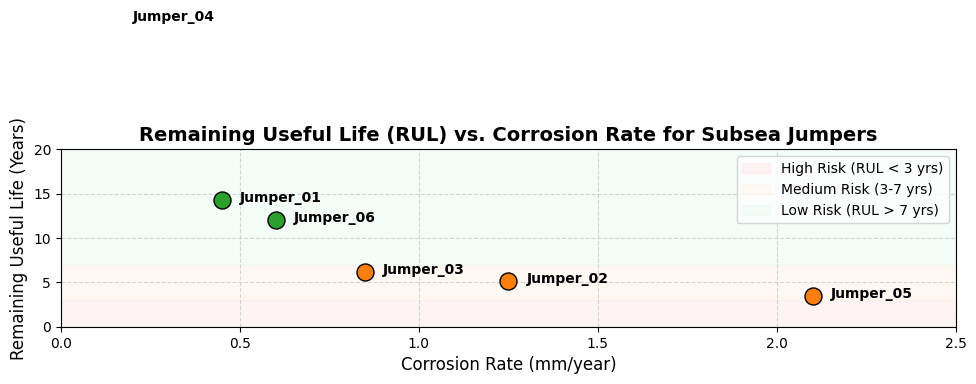

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Define the 6 jumpers from the case study
# Let's assume typical subsea jumper specs for wall thickness (e.g., initial 15mm-22mm, with a 3mm corrosion allowance)
jumpers_data = {
    'Jumper ID': ['Jumper_01', 'Jumper_02', 'Jumper_03', 'Jumper_04', 'Jumper_05', 'Jumper_06'],
    'Nominal_Thickness_mm': [19.1, 19.1, 15.4, 15.4, 22.2, 22.2],
    'Min_Allowable_Thickness_mm': [12.7, 12.7, 10.2, 10.2, 15.0, 15.0],
    # Let's assign different corrosion rates to represent varying operational exposures across different wells/flowlines
    'Corrosion_Rate_mm_yr': [0.45, 1.25, 0.85, 0.15, 2.10, 0.60]
}

df_jumpers = pd.DataFrame(jumpers_data)

# Remaining thickness budget before retirement
df_jumpers['Allowable_Loss_mm'] = df_jumpers['Nominal_Thickness_mm'] - df_jumpers['Min_Allowable_Thickness_mm']

# Remaining Useful Life (RUL) = Allowable Loss (mm) / Corrosion Rate (mm/year)
df_jumpers['RUL_years'] = df_jumpers['Allowable_Loss_mm'] / df_jumpers['Corrosion_Rate_mm_yr']

# Classify Risk based on RUL:
# High Risk: RUL < 3 years (Red)
# Medium Risk: 3 <= RUL <= 7 years (Orange)
# Low Risk: RUL > 7 years (Green)
def classify_risk(rul):
    if rul < 3.0:
        return 'High'
    elif rul <= 7.0:
        return 'Medium'
    else:
        return 'Low'

df_jumpers['Risk_Category'] = df_jumpers['RUL_years'].apply(classify_risk)

print("--- Jumper Integrity Status & RUL ---")
print(df_jumpers[['Jumper ID', 'Nominal_Thickness_mm', 'Corrosion_Rate_mm_yr', 'RUL_years', 'Risk_Category']])

# Set up colors for plotting
colors = {'High': '#d62728', 'Medium': '#ff7f0e', 'Low': '#2ca02c'}

# Plotting
plt.figure(figsize=(10, 6))

# Create background zones for risk
plt.axhspan(0, 3, color='#fde8e8', alpha=0.5, label='High Risk (RUL < 3 yrs)')
plt.axhspan(3, 7, color='#fff3e6', alpha=0.5, label='Medium Risk (3-7 yrs)')
plt.axhspan(7, 30, color='#eafaf1', alpha=0.5, label='Low Risk (RUL > 7 yrs)')

# Scatter plot for each jumper
for idx, row in df_jumpers.iterrows():
    plt.scatter(row['Corrosion_Rate_mm_yr'], row['RUL_years'],
                color=colors[row['Risk_Category']], s=150, zorder=5, edgecolor='black')
    plt.text(row['Corrosion_Rate_mm_yr'] + 0.05, row['RUL_years'] - 0.2,
             row['Jumper ID'], fontsize=10, fontweight='bold', zorder=6)

plt.title('Remaining Useful Life (RUL) vs. Corrosion Rate for Subsea Jumpers', fontsize=14, fontweight='bold')
plt.xlabel('Corrosion Rate (mm/year)', fontsize=12)
plt.ylabel('Remaining Useful Life (Years)', fontsize=12)
plt.xlim(0, 2.5)
plt.ylim(0, 20)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()